# **Time Series Analysis and Forecasting**

## Overview:

Time series forecasting is the process of using historical data points collected sequentially over time to predict future values.

The key difference from a typical machine learning problem is that time and temporal dependencies matter. In time series data, the value at a particular point can depend on previous observations, trends, seasonality, and sometimes external factors.

So, in simple terms Time series forecasting is about understanding patterns in historical time-dependent data and using those patterns to make predictions about the future.

## Types of Time Series
1. **Univariate**: A univariate time series records only one variable over time, making it simpler to analyze and model.
2. **Multivariate**: A multivariate time series tracks multiple related variables together to show how they influence each other over time.

## Components of Time Series Data / Time series decomposition:

Time series data generally has four main components: trend, seasonality, cyclical variation, and irregular or random variation

### Time series decomposition:
Time series decomposition means breaking a time series into smaller components so we can understand what is driving the data.

Decomposition = separating a time series into its underlying patterns.
**Time Series = Trend + Seasonality + Cyclical + Irregular/Noise**


1. **Trends**:
A trend signifies a long-term directional movement in the data, which can be either increasing or decreasing over time.It captures the overall upward or downward movement over time. Trends can be linear or nonlinear.
2. **Seasonality**:
Seasonality is a pattern that repeats at a fixed interval of time. It usually happens because of factors such as seasons, holidays, weekdays, or regular business cycles.

3. **Cyclical Variations**:
Cyclical variations are long-term rises and falls in a time series that occur around the overall trend, usually because of broader economic, business, or market conditions.
unlike seasonality, cyclical patterns do not repeat at a fixed, known interval.

4. **Irregularity (Noise)**:
Noise is the random, unpredictable part of a time series that is not explained by trend, seasonality, or cycles.

In [1]:
# install the required module
!pip install yfinance pandas matplotlib statsmodels

In [2]:
# load indian stocks nifty50 data

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

# Download NIFTY 50 data
nifty_50 = yf.download(
    "^NSEI",
    start="2025-01-01",
    end="2026-01-01",
    auto_adjust=False
)

nifty_50.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI
Date,,,,,,
2025-01-01,23742.900391,23742.900391,23822.800781,23562.800781,23637.650391,154900
2025-01-02,24188.650391,24188.650391,24226.699219,23751.550781,23783.000000,283200
2025-01-03,24004.750000,24004.750000,24196.449219,23976.000000,24196.400391,312300
2025-01-06,23616.050781,23616.050781,24089.949219,23551.900391,24045.800781,278100
2025-01-07,23707.900391,23707.900391,23795.199219,23637.800781,23679.900391,262300


In [3]:
# print all columns

nifty_50 = nifty_50.droplevel('Ticker', axis=1)
nifty_50.head()

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2025-01-01,23742.900391,23742.900391,23822.800781,23562.800781,23637.650391,154900
2025-01-02,24188.650391,24188.650391,24226.699219,23751.550781,23783.000000,283200
2025-01-03,24004.750000,24004.750000,24196.449219,23976.000000,24196.400391,312300
2025-01-06,23616.050781,23616.050781,24089.949219,23551.900391,24045.800781,278100
2025-01-07,23707.900391,23707.900391,23795.199219,23637.800781,23679.900391,262300


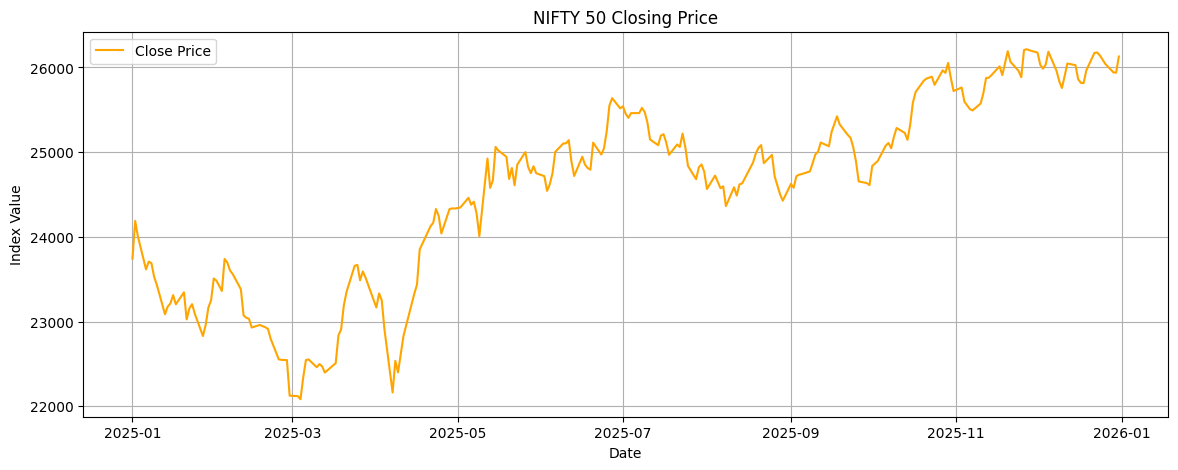

In [4]:
# plot the line plots for the Close price

plt.figure(figsize=(14, 5))

plt.plot(nifty_50['Close'], label="Close Price", color="orange")

plt.title("NIFTY 50 Closing Price")
plt.xlabel("Date")
plt.ylabel("Index Value")

plt.legend()
plt.grid(True)
plt.show()

In [5]:
# classicial Time Series Decomposition

from statsmodels.tsa.seasonal import seasonal_decompose

decomposition_additive = seasonal_decompose(
    nifty_50['Close'],
    model='additive',
    period=30  # as the data is daily, so we are telling look for a pattern that repeats every 30 trading observations(days)
)


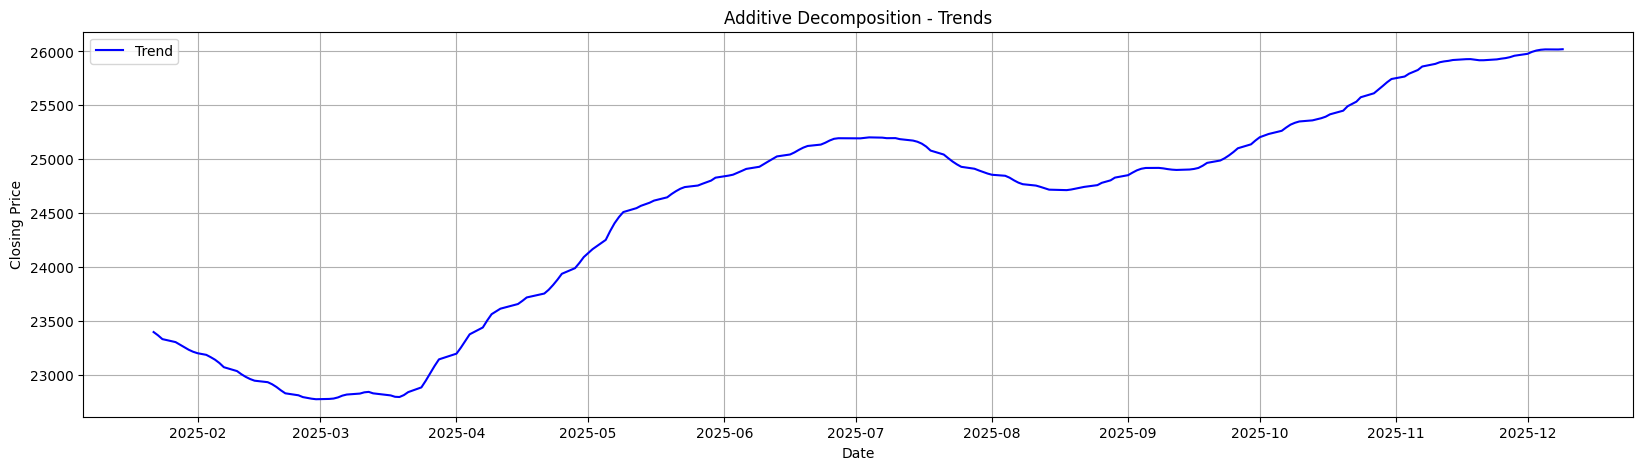

In [6]:
# from the above additive decomposition, find trend and plot it

trend_additive = decomposition_additive.trend

plt.figure(figsize=(20, 5))
plt.plot(trend_additive, label="Trend", color="blue")
plt.title("Additive Decomposition - Trends")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)
plt.show()

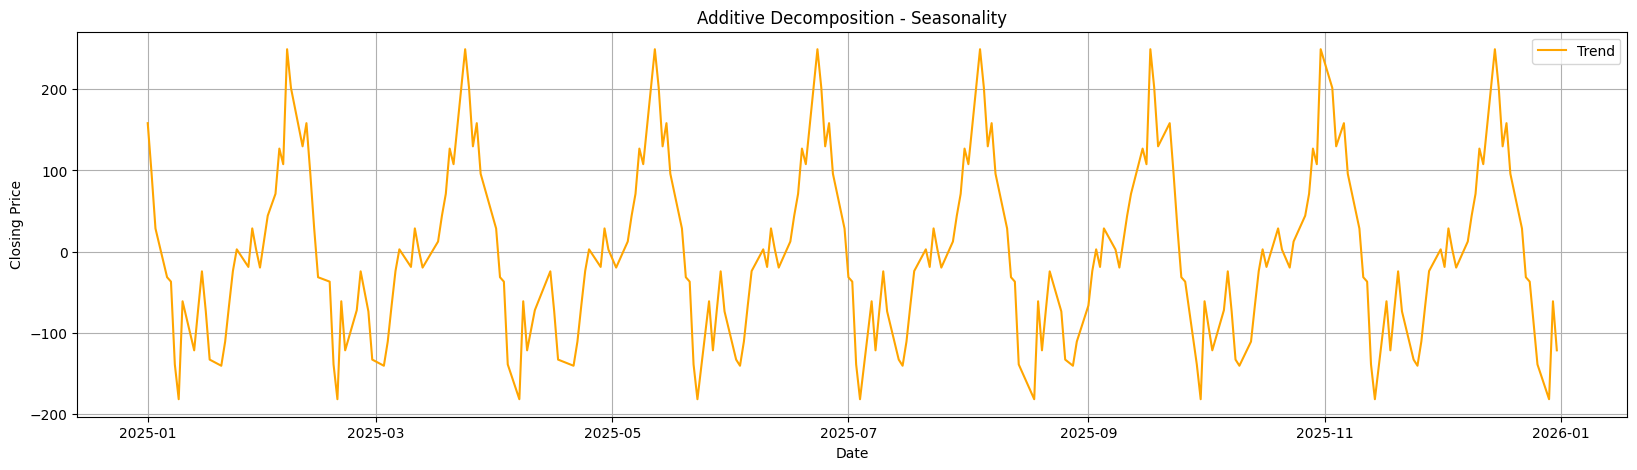

In [7]:
# from the above additive decomposition, find seasonality and plot it

seasonal_additive = decomposition_additive.seasonal

plt.figure(figsize=(20, 5))
plt.plot(seasonal_additive, label="Trend", color="Orange")
plt.title("Additive Decomposition - Seasonality")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)
plt.show()

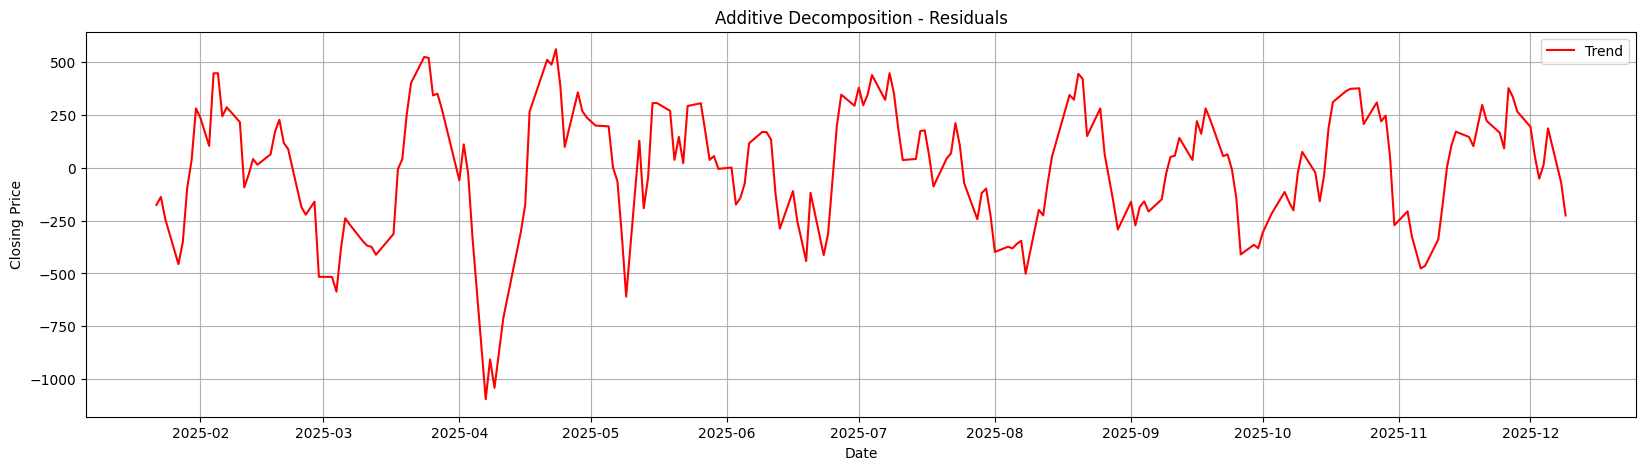

In [8]:
# from the above additive decomposition, find residuals and plot it

residual_additive = decomposition_additive.resid

plt.figure(figsize=(20, 5))
plt.plot(residual_additive, label="Trend", color="red")
plt.title("Additive Decomposition - Residuals")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)
plt.show()

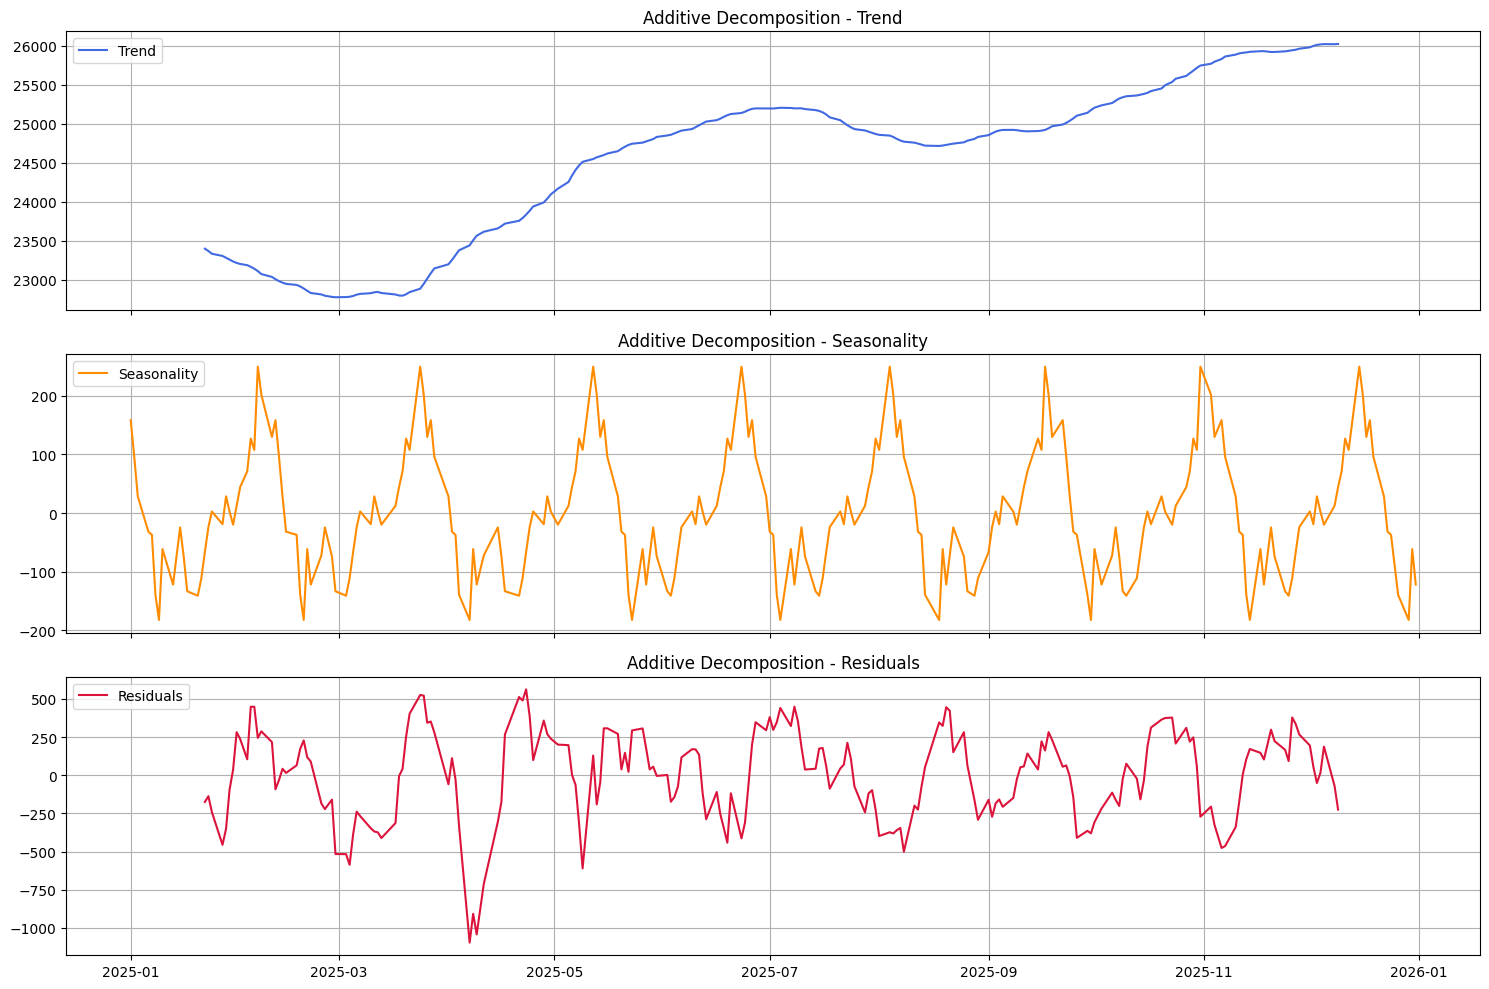

In [9]:
import matplotlib.pyplot as plt

# Clean, compact plotting with distinct colors
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

axes[0].plot(trend_additive, color='royalblue', label='Trend')
axes[1].plot(seasonal_additive, color='darkorange', label='Seasonality')
axes[2].plot(residual_additive, color='crimson', label='Residuals')

for ax, title in zip(axes, ['Trend', 'Seasonality', 'Residuals']):
    ax.set_title(f'Additive Decomposition - {title}')
    ax.grid(True)
    ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

## Decomposition Models:

The two main types of time-series **decomposition models** are:

1. **Additive decomposition**: Use it when the seasonal variation stays roughly the same size over time.

$$
Y_t = T_t + S_t + R_t
$$

2. **Multiplicative decomposition**: Use it when seasonal variation grows or shrinks with the level of the series.

$$
Y_t = T_t \times S_t \times R_t
$$

Use additive decomposition when seasonal fluctuations remain constant in magnitude, and multiplicative decomposition when seasonal variation changes proportionally with the level of the series.

### Visualizing Additive vs. Multiplicative Behaviors

To help visualize how the variance behaves in each model:

* **Additive**: The amplitude of seasonal variations remains constant over time regardless of the trend level.
* **Multiplicative**: The amplitude of seasonal variations increases or decreases proportionally with the level of the trend.

![Additive vs Multiplicative Visualization](https://miro.medium.com/1*LdeXlKrgNkFUjOhnO4Zzaw.jpeg)

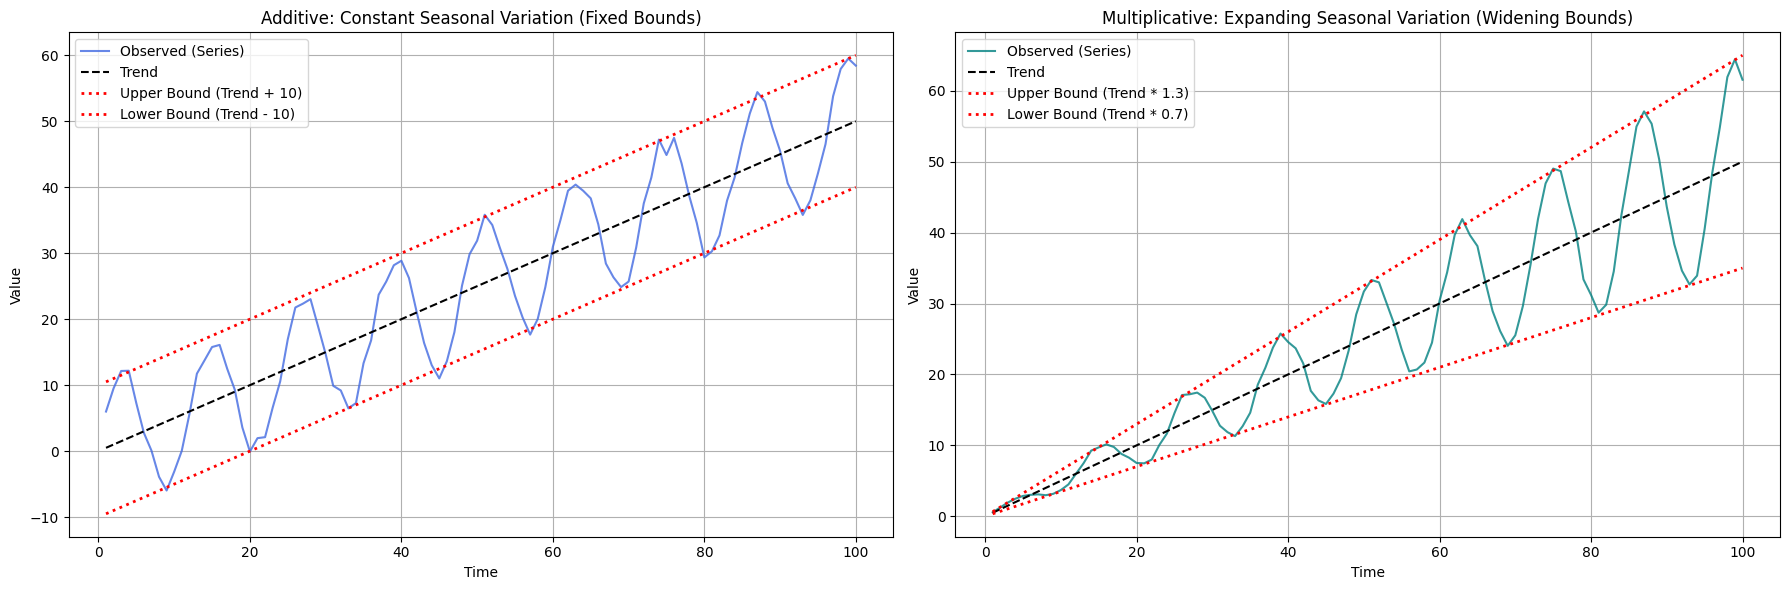

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Generate synthetic timeline
np.random.seed(42)
time = np.arange(1, 101)
trend = 0.5 * time

# 1. Additive Seasonality: Constant amplitude (+- 10)
seasonal_add = 10 * np.sin(2 * np.pi * time / 12)
noise_add = np.random.normal(0, 1, len(time))
series_add = trend + seasonal_add + noise_add
upper_bound_add = trend + 10
lower_bound_add = trend - 10

# 2. Multiplicative Seasonality: Growing amplitude as trend rises (* 1.3 and * 0.7)
seasonal_mult = (1.0 + 0.3 * np.sin(2 * np.pi * time / 12))
noise_mult = np.random.normal(1, 0.02, len(time))
series_mult = trend * seasonal_mult * noise_mult
upper_bound_mult = trend * 1.3
lower_bound_mult = trend * 0.7

# Plotting the visual difference
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Additive Plot with Bounds
axes[0].plot(time, series_add, color='royalblue', label='Observed (Series)', alpha=0.8)
axes[0].plot(time, trend, color='black', linestyle='--', label='Trend')
axes[0].plot(time, upper_bound_add, color='red', linestyle=':', linewidth=2, label='Upper Bound (Trend + 10)')
axes[0].plot(time, lower_bound_add, color='red', linestyle=':', linewidth=2, label='Lower Bound (Trend - 10)')
axes[0].set_title('Additive: Constant Seasonal Variation (Fixed Bounds)')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Value')
axes[0].grid(True)
axes[0].legend(loc='upper left')

# Multiplicative Plot with Bounds
axes[1].plot(time, series_mult, color='teal', label='Observed (Series)', alpha=0.8)
axes[1].plot(time, trend, color='black', linestyle='--', label='Trend')
axes[1].plot(time, upper_bound_mult, color='red', linestyle=':', linewidth=2, label='Upper Bound (Trend * 1.3)')
axes[1].plot(time, lower_bound_mult, color='red', linestyle=':', linewidth=2, label='Lower Bound (Trend * 0.7)')
axes[1].set_title('Multiplicative: Expanding Seasonal Variation (Widening Bounds)')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Value')
axes[1].grid(True)
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

## Seasonal-Trend Decomposition using Loess

* STL stands for Seasonal-Trend decomposition using Locally Estimated Scatterplot Smoothing.

* It is a technique that uses linear regression to smooth out data, making it particularly effective for handling outliers in time series datasets. While Classical decomposition assumes a fixed seasonal pattern, STL allows for changing seasonal variations over time.

* STL handles outliers but classical decompositions are influnced by outliers.

* STL only supports **additive models**. but, Classical decomposition can handle both additive and multiplicative models.

* **STL = flexible seasonality + LOESS + robust to outliers**



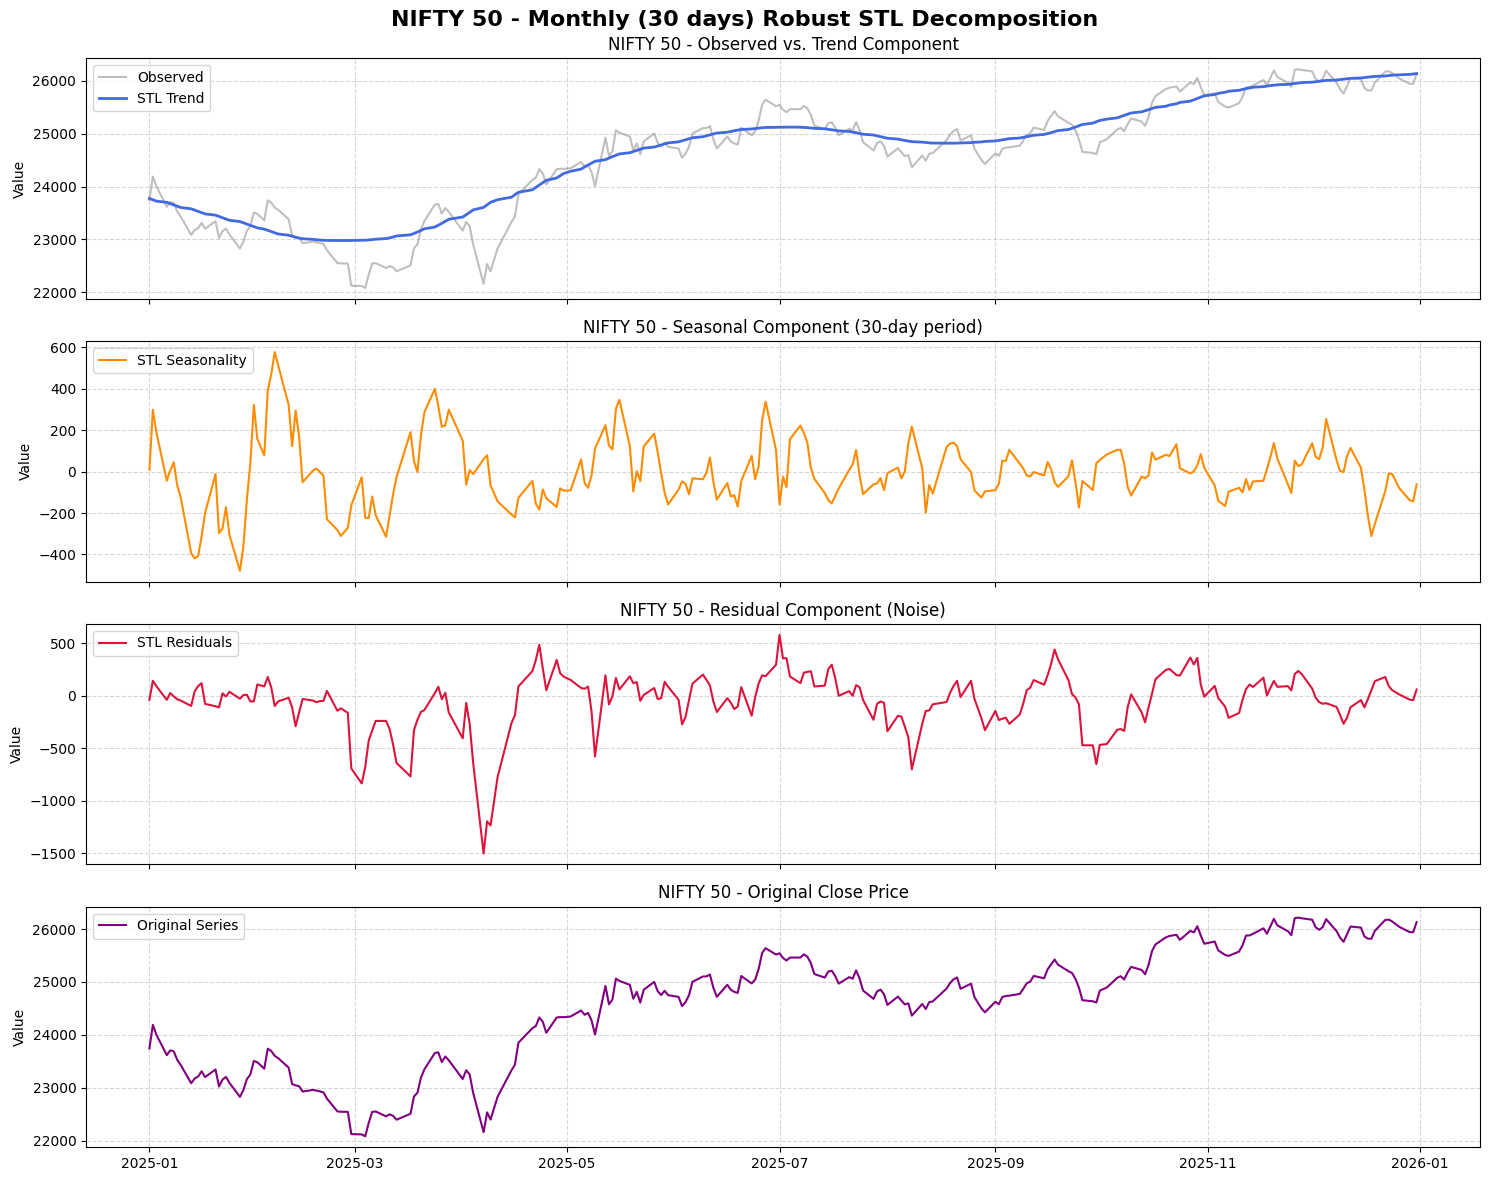

In [11]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

# 1. Fit the STL Decomposition
stl = STL(
    nifty_50['Close'],
    period=30,  # Look for a monthly (30 trading days) seasonal cycle
    robust=True
)
result = stl.fit()

# 2. Extract components
trend_stl = result.trend
seasonal_stl = result.seasonal
resid_stl = result.resid

# 3. Create a clean, customized multi-panel plot
fig, axes = plt.subplots(4, 1, figsize=(15, 12), sharex=True)

# Plot Observed alongside Trend
axes[0].plot(nifty_50['Close'], color='gray', alpha=0.5, label='Observed')
axes[0].plot(trend_stl, color='royalblue', linewidth=2, label='STL Trend')
axes[0].set_title('NIFTY 50 - Observed vs. Trend Component')

# Plot Seasonality
axes[1].plot(seasonal_stl, color='darkorange', label='STL Seasonality')
axes[1].set_title('NIFTY 50 - Seasonal Component (30-day period)')

# Plot Residuals
axes[2].plot(resid_stl, color='crimson', label='STL Residuals')
axes[2].set_title('NIFTY 50 - Residual Component (Noise)')

# Plot Observed again separately for standard STL comparison context
axes[3].plot(nifty_50['Close'], color='purple', label='Original Series')
axes[3].set_title('NIFTY 50 - Original Close Price')

# Apply general styling across all axes
for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper left')
    ax.set_ylabel('Value')

plt.suptitle("NIFTY 50 - Monthly (30 days) Robust STL Decomposition", fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

## Stationarity:

* A time series is considered stationary when its statistical properties—specifically its mean, variance, and auto-correlation—remain constant over time. It effectively means there is no underlying trend or fluctuating spread (variance) in the data.

* Most forecasting models, such as ARIMA or SARIMA, assumes that the input data is stationary. By ensuring that statistical properties are consistent, these models can more reliably predict future values based on past observations.

## Types of Stationarity:

* **Weak Stationarity**: Requires only that the mean, variance, and auto-correlation remain constant over time. and the joint probability distribution may change over time.

* **Strict Stationarity**: A time series is strictly stationary when its entire joint probability distribution remains unchanged regardless of the time period, encompassing all properties of weak stationarity.

* **Non-Stationary**: A non-stationary series shows changing patterns like trends or seasonality and often needs transformation before modeling

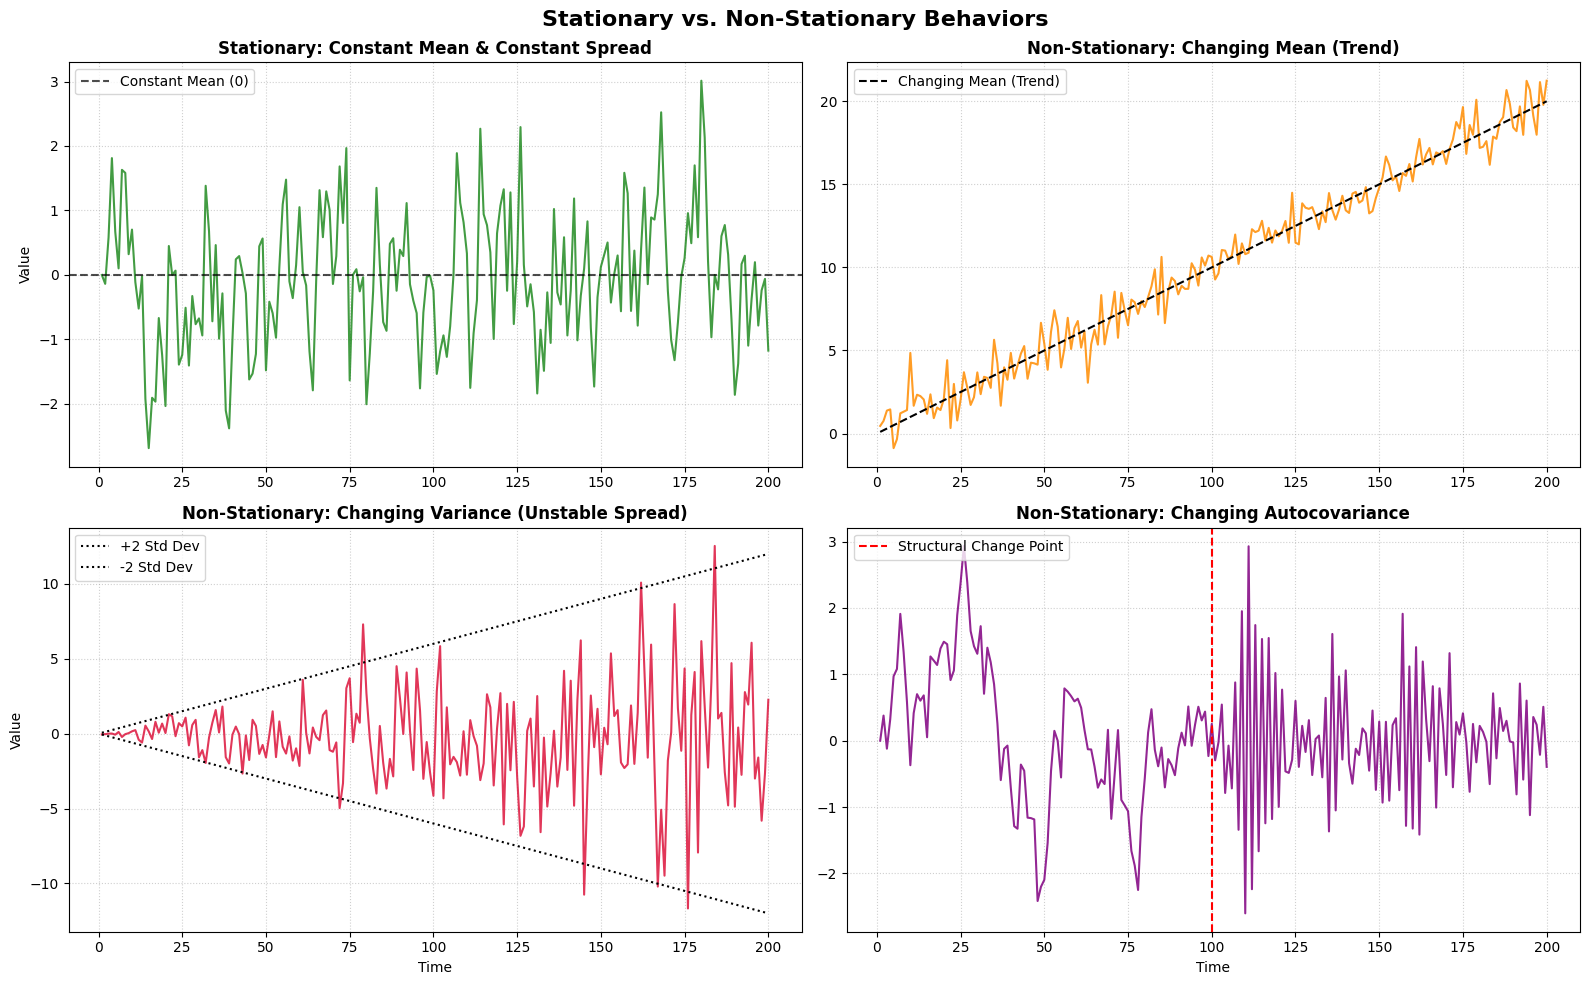

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Set seed for reproducibility
np.random.seed(42)
time = np.arange(1, 201)

# --- 1. Stationary Series (Constant Mean, Variance, and Autocovariance) ---
noise_stationary = np.random.normal(0, 1, len(time))
series_stationary = np.zeros(len(time))
# Create a stationary AR(1) process: y_t = 0.5 * y_{t-1} + e_t
for t in range(1, len(time)):
    series_stationary[t] = 0.5 * series_stationary[t-1] + noise_stationary[t]

# --- 2. Non-Stationary: Changing Mean (Trend exists) ---
series_trend = 0.1 * time + np.random.normal(0, 1, len(time))

# --- 3. Non-Stationary: Changing Variance (Heteroscedasticity) ---
# Spread increases exponentially or linearly over time
variance_scale = 0.03 * time
series_variance = np.random.normal(0, 1, len(time)) * variance_scale

# --- 4. Non-Stationary: Changing Covariance (Structural Change) ---
# Low frequency dependency in first half, high frequency in second half
series_covariance = np.zeros(len(time))
for t in range(1, len(time)):
    if t < 100:
        series_covariance[t] = 0.9 * series_covariance[t-1] + np.random.normal(0, 0.5)
    else:
        series_covariance[t] = -0.8 * series_covariance[t-1] + np.random.normal(0, 0.5)

# --- Plotting the grid comparing Stationary vs. Non-Stationary ---
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Subplot 1: Stationary
axes[0, 0].plot(time, series_stationary, color='forestgreen', alpha=0.85)
axes[0, 0].axhline(y=0, color='black', linestyle='--', alpha=0.7, label='Constant Mean (0)')
axes[0, 0].set_title('Stationary: Constant Mean & Constant Spread', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Value')
axes[0, 0].legend(loc='upper left')
axes[0, 0].grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Non-Stationary - Changing Mean
axes[0, 1].plot(time, series_trend, color='darkorange', alpha=0.85)
axes[0, 1].plot(time, 0.1 * time, color='black', linestyle='--', label='Changing Mean (Trend)')
axes[0, 1].set_title('Non-Stationary: Changing Mean (Trend)', fontsize=12, fontweight='bold')
axes[0, 1].legend(loc='upper left')
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# Subplot 3: Non-Stationary - Changing Variance
axes[1, 0].plot(time, series_variance, color='crimson', alpha=0.85)
axes[1, 0].plot(time, 2 * variance_scale, color='black', linestyle=':', label='+2 Std Dev')
axes[1, 0].plot(time, -2 * variance_scale, color='black', linestyle=':', label='-2 Std Dev')
axes[1, 0].set_title('Non-Stationary: Changing Variance (Unstable Spread)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Time')
axes[1, 0].set_ylabel('Value')
axes[1, 0].legend(loc='upper left')
axes[1, 0].grid(True, linestyle=':', alpha=0.6)

# Subplot 4: Non-Stationary - Changing Covariance
axes[1, 1].plot(time, series_covariance, color='purple', alpha=0.85)
axes[1, 1].axvline(x=100, color='red', linestyle='--', label='Structural Change Point')
axes[1, 1].set_title('Non-Stationary: Changing Autocovariance', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Time')
axes[1, 1].legend(loc='upper left')
axes[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Stationary vs. Non-Stationary Behaviors', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

## Stationarity Tests in Time Series Analysis

### **Weak Stationarity Tests**

The two most common statistical tests for verifying weak stationarity are:

#### **1. ADF (Augmented Dickey-Fuller) Test**
ADF is a statistical test used to check whether a time series has a unit root (a non-stationary trend), which indicates that the series is non-stationary.
* **$H_0$ (Null Hypothesis):** The series is non-stationary (contains a unit root).
* **$H_1$ (Alternative Hypothesis):** The series is stationary.
* **Decision Rule:** $p\text{-value} < 0.05$ $\rightarrow$ Reject $H_0$ $\rightarrow$ The series is likely **stationary**.

#### **2. KPSS (Kwiatkowski–Phillips–Schmidt–Shin) Test**
KPSS is a statistical test used to check whether a time series is stationary around a constant mean or a deterministic trend.
* **$H_0$ (Null Hypothesis):** The series is stationary.
* **$H_1$ (Alternative Hypothesis):** The series is non-stationary.
* **Decision Rule:** $p\text{-value} < 0.05$ $\rightarrow$ Reject $H_0$ $\rightarrow$ The series is likely **non-stationary**.


### **Strict Stationarity Tests**

#### **3. Kolmogorov-Smirnov (K-S) Test**
The Kolmogorov-Smirnov test is specifically used to check for strict stationarity by comparing the cumulative distribution functions (CDFs) of two different samples within the time series.
* **Methodology:** It splits the time series into separate sub-samples and compares their distributions.
* **Decision Rule:** A high $p\text{-value}$ ($> 0.05$) suggests there is no statistically significant difference in distribution between the samples, implying **strict stationarity**.

In [13]:
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller

close_prices = nifty_50['Close'].dropna()


# 1. Augmented Dickey-Fuller (ADF) Test (Weak Stationarity)
print("\n--- [1] Augmented Dickey-Fuller (ADF) Test ---")
adf_result = adfuller(close_prices)
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4f}")
print("Critical Values:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value:.4f}")

if adf_result[1] < 0.05:
    print("Conclusion: Reject H₀. The series is likely STATIONARY.")
else:
    print("Conclusion: Fail to reject H₀. The series is likely NON-STATIONARY.")



--- [1] Augmented Dickey-Fuller (ADF) Test ---
ADF Statistic: -0.9981
p-value: 0.7539
Critical Values:
   1%: -3.4570
   5%: -2.8733
   10%: -2.5730
Conclusion: Fail to reject H₀. The series is likely NON-STATIONARY.


In [14]:
from statsmodels.tsa.stattools import kpss

# Drop any missing values in the close price series to avoid testing errors
close_prices = nifty_50['Close'].dropna()

# 2. KPSS Test (Weak Stationarity)
print("\n--- [2] KPSS Test ---")

# 'ct' specifies stationary around a trend, 'c' around a constant mean
kpss_result = kpss(close_prices, regression='c', nlags='auto')
print(f"KPSS Statistic: {kpss_result[0]:.4f}")
print(f"p-value: {kpss_result[1]:.4f}")
print("Critical Values:")
for key, value in kpss_result[3].items():
    print(f"   {key}: {value:.4f}")

if kpss_result[1] < 0.05:
    print("Conclusion: Reject H₀. The series is likely NON-STATIONARY.")
else:
    print("Conclusion: Fail to reject H₀. The series is likely STATIONARY.")



--- [2] KPSS Test ---
KPSS Statistic: 1.9127
p-value: 0.0100
Critical Values:
   10%: 0.3470
   5%: 0.4630
   2.5%: 0.5740
   1%: 0.7390
Conclusion: Reject H₀. The series is likely NON-STATIONARY.


/tmp/ipykernel_2887/3275153336.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(close_prices, regression='c', nlags='auto')


In [15]:
from scipy.stats import ks_2samp

# Drop any missing values in the close price series to avoid testing errors
close_prices = nifty_50['Close'].dropna()

# 3. Kolmogorov-Smirnov (K-S) Test (Strict Stationarity)
print("\n--- [3] Kolmogorov-Smirnov (K-S) Test ---")

# Split the series into two halves to compare their probability distributions
midpoint = len(close_prices) // 2
sample_1 = close_prices.iloc[:midpoint]
sample_2 = close_prices.iloc[midpoint:]

ks_stat, ks_p_value = ks_2samp(sample_1, sample_2)
print(f"KS Statistic: {ks_stat:.4f}")
print(f"p-value: {ks_p_value:.4e}")

if ks_p_value > 0.05:
    print("Conclusion: High p-value. Cumulative distributions are similar (suggests STRICT STATIONARITY).")
else:
    print("Conclusion: Low p-value. Cumulative distributions are significantly different (NON-STATIONARY).")


--- [3] Kolmogorov-Smirnov (K-S) Test ---
KS Statistic: 0.6856
p-value: 2.6273e-28
Conclusion: Low p-value. Cumulative distributions are significantly different (NON-STATIONARY).


# Techniques to Make Non-Stationary Time Series Stationary

A time series is stationary when its statistical properties—such as mean, variance, and autocovariance—are stable over time. A common workflow is to identify the source of non-stationarity, apply an appropriate transformation, and then verify stationarity using tests such as ADF and KPSS.

There are **4 main approaches** to convert non-stationary data into stationary:

1. **Differencing**
   * Subtracting past values from current observations to remove trends and seasonality. This includes first-order and second-order differencing.

2. **Transformation**
   * Used to stabilize the variance of the data, covering logarithmic, power (like square root), and Box-Cox transformations.
   * **Log transformation** converts the original values to their logarithms and is commonly used when the variance increases with the level of the time series.
   * A **square-root transformation** reduces the effect of large values and can be used to stabilize variance, particularly for count-type data.
   * **Box-Cox transformation**:
     Instead of manually deciding whether to use a log or square-root transformation, Box-Cox provides a parameter lambda that determines the appropriate power transformation.

     * λ = 1: No transformation
     * λ = 0.5: Square root
     * λ = 0: Log
     * λ = -1: Reciprocal

3. **Detrending**
   * Removing the trend component from data, typically using linear detrending (fitting a regression line) or moving average techniques.

4. **Seasonal Adjustment**
   * Removing seasonal components from the data, often performed using techniques like STL decomposition or classical decomposition.

### **Helper Function for Stationarity Testing**
We will define a helper function `check_stationarity` that performs both the Augmented Dickey-Fuller (ADF) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests to make verifying stationarity easy.

In [16]:
from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

def check_stationarity(series, title="Time Series"):
    series = pd.Series(series).dropna()
    print(f"\n{'='*10} Stationarity Analysis: {title} {'='*10}")

    # 1. ADF Test
    adf_res = adfuller(series)
    adf_stat, adf_p = adf_res[0], adf_res[1]
    is_adf_stationary = adf_p < 0.05

    # 2. KPSS Test
    kpss_res = kpss(series, regression='c', nlags='auto')
    kpss_stat, kpss_p = kpss_res[0], kpss_res[1]
    is_kpss_stationary = kpss_p >= 0.05

    # Print Results
    print(f"[ADF Test]  Stat: {adf_stat:.4f}, p-value: {adf_p:.4f} -> Conclusion: {'STATIONARY' if is_adf_stationary else 'NON-STATIONARY'}")
    print(f"[KPSS Test] Stat: {kpss_stat:.4f}, p-value: {kpss_p:.4f} -> Conclusion: {'STATIONARY' if is_kpss_stationary else 'NON-STATIONARY'}")

    if is_adf_stationary and is_kpss_stationary:
        print("==> Overall Verdict: Strong evidence of STATIONARITY (Both tests agree).")
    elif not is_adf_stationary and not is_kpss_stationary:
        print("==> Overall Verdict: Strong evidence of NON-STATIONARITY (Both tests agree).")
    else:
        print("==> Overall Verdict: Mixed signals / Trend-stationarity suspected. Exercise caution.")


### **Technique 1: Differencing**
Subtracting past values from current observations to remove trends and seasonality.


========== Stationarity Analysis: Original Close Prices ==========
[ADF Test]  Stat: -0.9981, p-value: 0.7539 -> Conclusion: NON-STATIONARY
[KPSS Test] Stat: 1.9127, p-value: 0.0100 -> Conclusion: NON-STATIONARY
==> Overall Verdict: Strong evidence of NON-STATIONARITY (Both tests agree).

========== Stationarity Analysis: First-Order Differenced Prices ==========
[ADF Test]  Stat: -15.6484, p-value: 0.0000 -> Conclusion: STATIONARY
[KPSS Test] Stat: 0.0578, p-value: 0.1000 -> Conclusion: STATIONARY
==> Overall Verdict: Strong evidence of STATIONARITY (Both tests agree).


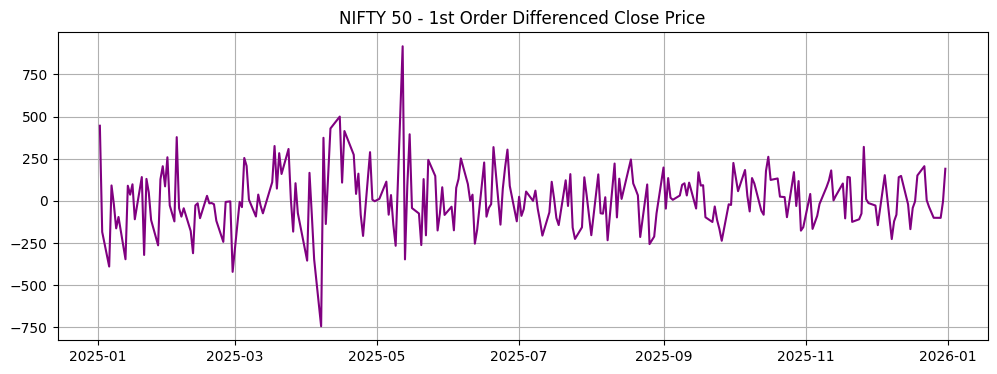

In [17]:
close_prices = nifty_50['Close'].dropna()

# Before differencing
check_stationarity(close_prices, "Original Close Prices")

# Apply 1st order Differencing
diff_prices = close_prices.diff().dropna()

# After differencing
check_stationarity(diff_prices, "First-Order Differenced Prices")

# Plotting
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 4))
plt.plot(diff_prices, color='purple')
plt.title("NIFTY 50 - 1st Order Differenced Close Price")
plt.grid(True)
plt.show()

### **Technique 2: Transformations (Log, Square Root, and Box-Cox)**
Let's apply logarithmic, square root, and Box-Cox transformations and check their impact on stationarity.

In [18]:
from scipy.stats import boxcox

close_prices = nifty_50['Close'].dropna()

# 1. Log Transformation
log_prices = np.log(close_prices)
check_stationarity(log_prices, "Log Transformed Prices")

# 2. Square Root Transformation
sqrt_prices = np.sqrt(close_prices)
check_stationarity(sqrt_prices, "Square Root Transformed Prices")

# 3. Box-Cox Transformation
boxcox_prices, fitted_lambda = boxcox(close_prices)
check_stationarity(boxcox_prices, f"Box-Cox Transformed Prices (λ = {fitted_lambda:.4f})")


========== Stationarity Analysis: Log Transformed Prices ==========
[ADF Test]  Stat: -1.0300, p-value: 0.7422 -> Conclusion: NON-STATIONARY
[KPSS Test] Stat: 1.8981, p-value: 0.0100 -> Conclusion: NON-STATIONARY
==> Overall Verdict: Strong evidence of NON-STATIONARITY (Both tests agree).

========== Stationarity Analysis: Square Root Transformed Prices ==========
[ADF Test]  Stat: -1.0138, p-value: 0.7482 -> Conclusion: NON-STATIONARY
[KPSS Test] Stat: 1.9056, p-value: 0.0100 -> Conclusion: NON-STATIONARY
==> Overall Verdict: Strong evidence of NON-STATIONARITY (Both tests agree).

========== Stationarity Analysis: Box-Cox Transformed Prices (λ = 6.8388) ==========
[ADF Test]  Stat: 0.7174, p-value: 0.9902 -> Conclusion: NON-STATIONARY
[KPSS Test] Stat: 1.9673, p-value: 0.0100 -> Conclusion: NON-STATIONARY
==> Overall Verdict: Strong evidence of NON-STATIONARITY (Both tests agree).


### **Technique 3: Detrending**
Removing the long-term trend component using a linear regression model on the time index.


========== Stationarity Analysis: Original Close Prices ==========
[ADF Test]  Stat: -0.9981, p-value: 0.7539 -> Conclusion: NON-STATIONARY
[KPSS Test] Stat: 1.9127, p-value: 0.0100 -> Conclusion: NON-STATIONARY
==> Overall Verdict: Strong evidence of NON-STATIONARITY (Both tests agree).

========== Stationarity Analysis: Linear Detrended Prices ==========
[ADF Test]  Stat: -2.8938, p-value: 0.0461 -> Conclusion: STATIONARY
[KPSS Test] Stat: 0.1637, p-value: 0.1000 -> Conclusion: STATIONARY
==> Overall Verdict: Strong evidence of STATIONARITY (Both tests agree).


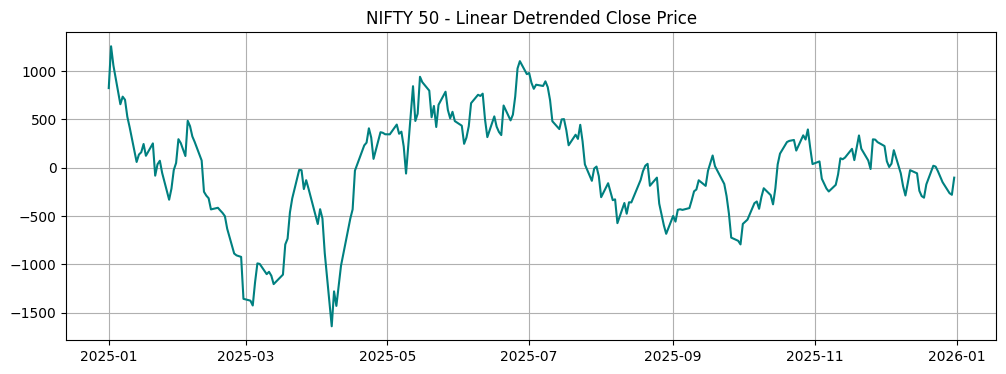

In [19]:
from sklearn.linear_model import LinearRegression

close_prices = nifty_50['Close'].dropna()

# Before detrending
check_stationarity(close_prices, "Original Close Prices")

# Fit linear regression to model the trend
X = np.arange(len(close_prices)).reshape(-1, 1)
y = close_prices.values
model = LinearRegression().fit(X, y)
trend_pred = model.predict(X)

# Subtract predicted linear trend from original values
detrended_prices = close_prices - trend_pred

# After detrending
check_stationarity(detrended_prices, "Linear Detrended Prices")

# Plotting
plt.figure(figsize=(12, 4))
plt.plot(close_prices.index, detrended_prices, color='teal')
plt.title("NIFTY 50 - Linear Detrended Close Price")
plt.grid(True)
plt.show()

### **Technique 4: Seasonal Adjustment**
Subtracting the seasonal component obtained via robust STL decomposition.


========== Stationarity Analysis: Original Close Prices ==========
[ADF Test]  Stat: -0.9981, p-value: 0.7539 -> Conclusion: NON-STATIONARY
[KPSS Test] Stat: 1.9127, p-value: 0.0100 -> Conclusion: NON-STATIONARY
==> Overall Verdict: Strong evidence of NON-STATIONARITY (Both tests agree).

========== Stationarity Analysis: Seasonally Adjusted Prices (STL) ==========
[ADF Test]  Stat: -0.8476, p-value: 0.8047 -> Conclusion: NON-STATIONARY
[KPSS Test] Stat: 1.9290, p-value: 0.0100 -> Conclusion: NON-STATIONARY
==> Overall Verdict: Strong evidence of NON-STATIONARITY (Both tests agree).


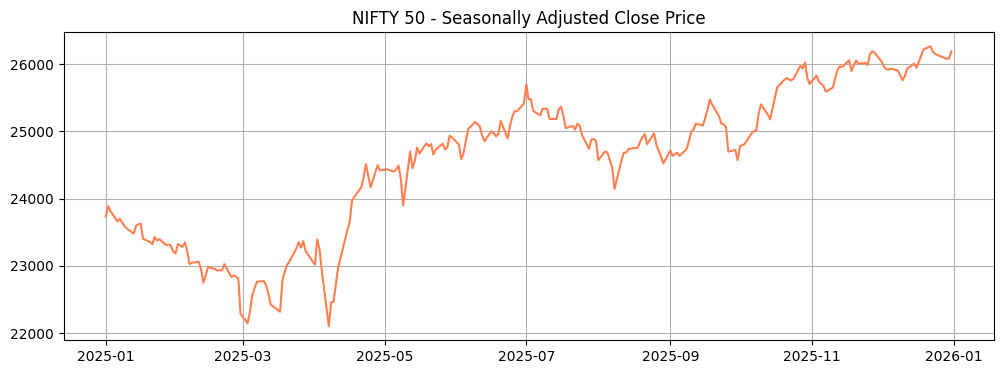

In [20]:
from statsmodels.tsa.seasonal import STL

close_prices = nifty_50['Close'].dropna()

# Before seasonal adjustment
check_stationarity(close_prices, "Original Close Prices")

# Extract seasonality via STL
stl = STL(close_prices, period=30, robust=True)
result = stl.fit()

# Subtract the seasonal component
seasonally_adjusted = close_prices - result.seasonal

# After seasonal adjustment
check_stationarity(seasonally_adjusted, "Seasonally Adjusted Prices (STL)")

# Plotting
plt.figure(figsize=(12, 4))
plt.plot(close_prices.index, seasonally_adjusted, color='coral')
plt.title("NIFTY 50 - Seasonally Adjusted Close Price")
plt.grid(True)
plt.show()

### **Checking Stationarity visually with a Trendline and Rolling Moving Average**
To visually inspect stationarity, we can plot the original time series alongside:
1. A fitted **Linear Trendline** to see if the overall mean changes continuously over the entire period.
2. A **Rolling Moving Average** (e.g., 20-day window) to see how the local mean behaves over time.

### **Visual Check 1: Linear Trendline**
We will fit and plot a linear regression trendline directly over the original NIFTY 50 Close prices to check if the long-term mean is constant or changing over time.

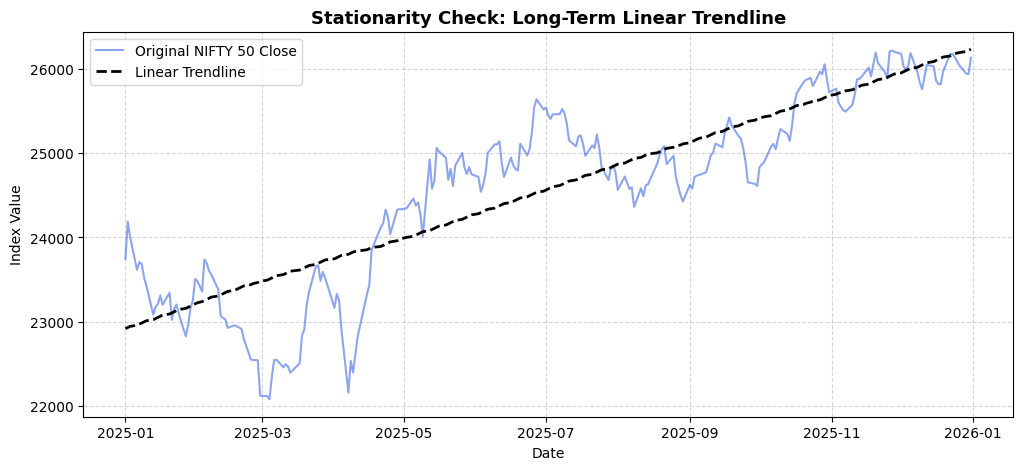

The fitted trendline has an upward slope, indicating that the mean increases over time (Non-Stationary).


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Prepare data
close_prices = nifty_50['Close'].dropna()

# Fit Linear Trendline
X = np.arange(len(close_prices)).reshape(-1, 1)
y = close_prices.values
trend_model = LinearRegression().fit(X, y)
trendline = pd.Series(trend_model.predict(X), index=close_prices.index)

# Plotting
plt.figure(figsize=(12, 5))
plt.plot(close_prices, label="Original NIFTY 50 Close", color="royalblue", alpha=0.6)
plt.plot(trendline, label="Linear Trendline", color="black", linestyle="--", linewidth=2)
plt.title("Stationarity Check: Long-Term Linear Trendline", fontsize=13, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Index Value")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print(f"The fitted trendline has an upward slope, indicating that the mean increases over time (Non-Stationary).")

### **Visual Check 2: Rolling Moving Average (MA) and Variance**
We will calculate and plot the 20-day rolling mean alongside the rolling standard deviation bounds to examine whether the local mean and volatility remain stable over time.

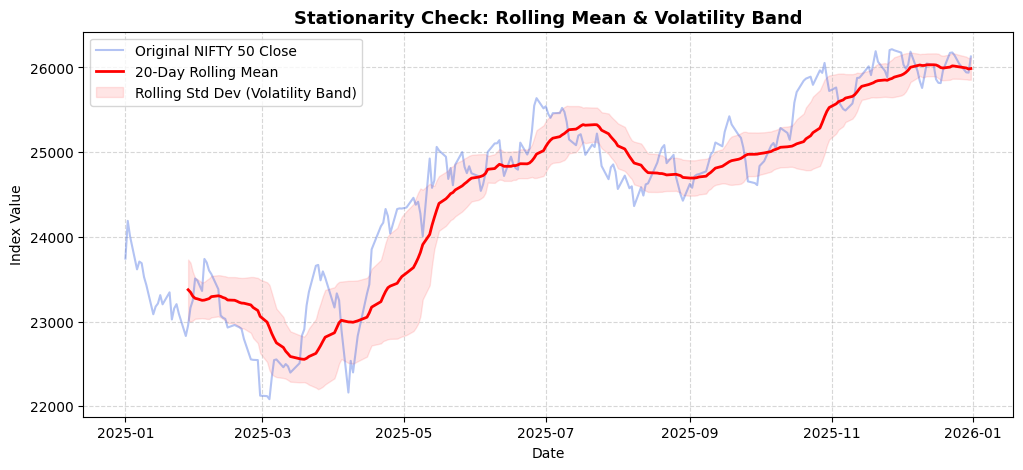

The moving average varies with time and the volatility band width fluctuates, indicating both unstable mean and variance (Non-Stationary).


In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Prepare data
close_prices = nifty_50['Close'].dropna()

# Compute 20-day rolling metrics
rolling_window = 20
rolling_mean = close_prices.rolling(window=rolling_window).mean()
rolling_std = close_prices.rolling(window=rolling_window).std()

# Plotting
plt.figure(figsize=(12, 5))
plt.plot(close_prices, label="Original NIFTY 50 Close", color="royalblue", alpha=0.4)
plt.plot(rolling_mean, label=f"{rolling_window}-Day Rolling Mean", color="red", linewidth=2)
plt.fill_between(close_prices.index, rolling_mean - rolling_std, rolling_mean + rolling_std,
                 color="red", alpha=0.1, label="Rolling Std Dev (Volatility Band)")
plt.title("Stationarity Check: Rolling Mean & Volatility Band", fontsize=13, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Index Value")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("The moving average varies with time and the volatility band width fluctuates, indicating both unstable mean and variance (Non-Stationary).")

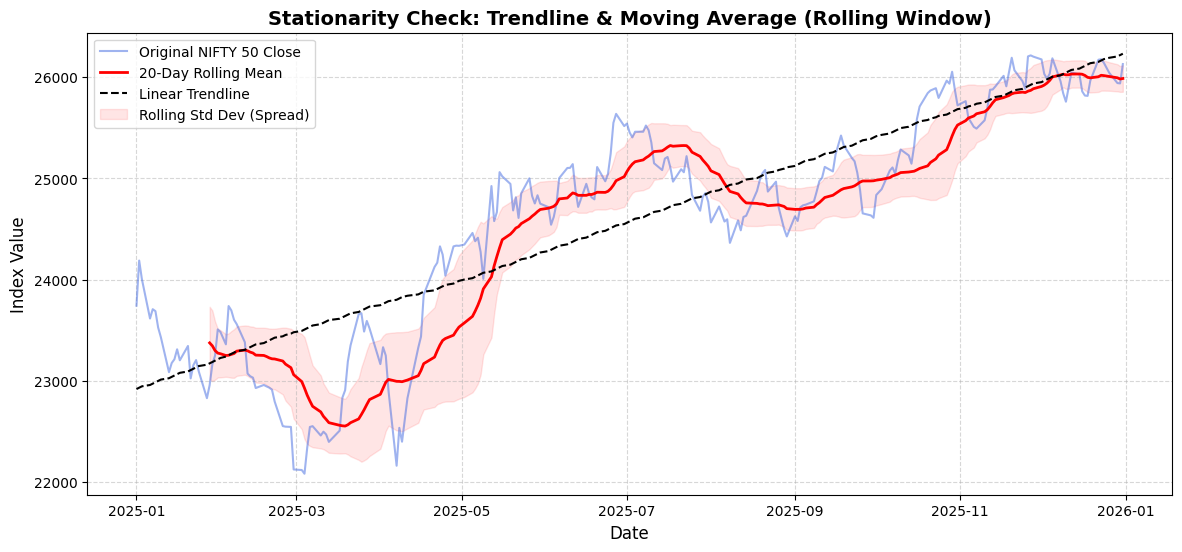

Visual Diagnosis:
- The upward slope of both the Linear Trendline and the Rolling Mean indicates a CHANGING MEAN over time.
- The thickness of the Rolling Std Dev band also changes, indicating potentially unstable VARIANCE.
==> Since statistical properties depend on time, the original series is visually confirmed to be NON-STATIONARY.


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1. Prepare data
close_prices = nifty_50['Close'].dropna()

# 2. Compute 20-day Rolling Moving Average and Standard Deviation
rolling_window = 20
rolling_mean = close_prices.rolling(window=rolling_window).mean()
rolling_std = close_prices.rolling(window=rolling_window).std()

# 3. Fit Linear Trendline
X = np.arange(len(close_prices)).reshape(-1, 1)
y = close_prices.values
trend_model = LinearRegression().fit(X, y)
trendline = pd.Series(trend_model.predict(X), index=close_prices.index)

# 4. Plotting
plt.figure(figsize=(14, 6))
plt.plot(close_prices, label="Original NIFTY 50 Close", color="royalblue", alpha=0.5)
plt.plot(rolling_mean, label=f"{rolling_window}-Day Rolling Mean", color="red", linewidth=2)
plt.plot(trendline, label="Linear Trendline", color="black", linestyle="--", linewidth=1.5)
plt.fill_between(close_prices.index, rolling_mean - rolling_std, rolling_mean + rolling_std,
                 color="red", alpha=0.1, label="Rolling Std Dev (Spread)")

plt.title("Stationarity Check: Trendline & Moving Average (Rolling Window)", fontsize=14, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Index Value", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Quick visual conclusion
print("Visual Diagnosis:")
print("- The upward slope of both the Linear Trendline and the Rolling Mean indicates a CHANGING MEAN over time.")
print("- The thickness of the Rolling Std Dev band also changes, indicating potentially unstable VARIANCE.")
print("==> Since statistical properties depend on time, the original series is visually confirmed to be NON-STATIONARY.")

### **Visual Check 3: Classical Seasonal Decomposition (Additive vs. Multiplicative)**
We can decompose the NIFTY 50 Close price to isolate the long-term trend, the cyclical/seasonal fluctuations, and the residual noise to visually determine which parts contribute to the non-stationarity of the series.

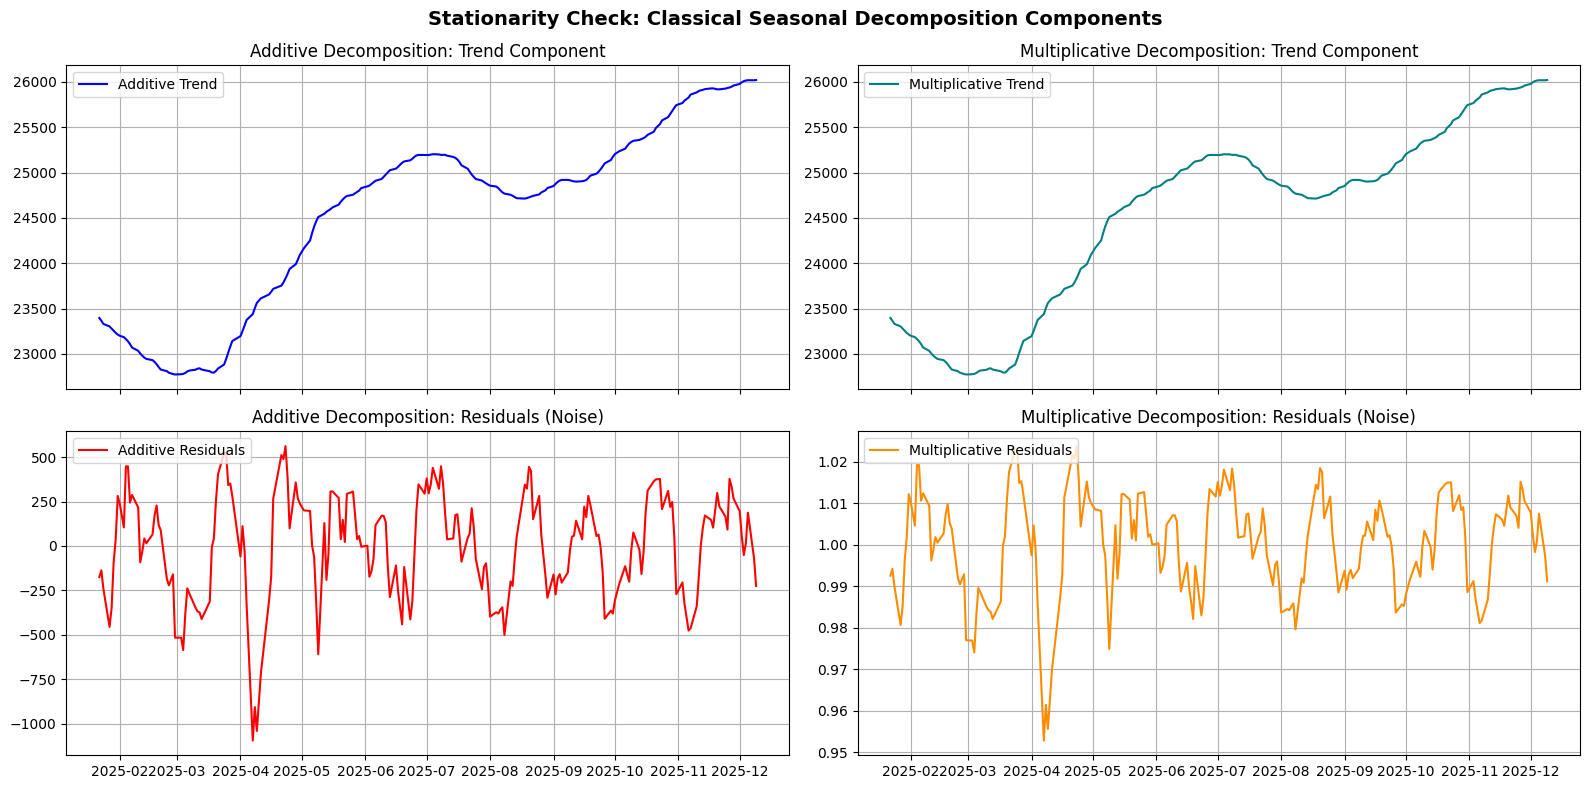

Visual Diagnosis:
- The isolated Trends (both Additive & Multiplicative) change over time, showing a strong non-stationary mean.
- The residuals (noise) show stability around a constant level, hinting at stationarity once trends are fully removed.


In [24]:
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Prepare data
close_prices = nifty_50['Close'].dropna()

# Perform classical additive and multiplicative decomposition
decomp_add = seasonal_decompose(close_prices, model='additive', period=30)
decomp_mult = seasonal_decompose(close_prices, model='multiplicative', period=30)

# Plotting Additive vs Multiplicative Trends & Residuals
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True)

# Additive Trend & Residuals
axes[0, 0].plot(decomp_add.trend, color='blue', label='Additive Trend')
axes[0, 0].set_title("Additive Decomposition: Trend Component")
axes[0, 0].grid(True)
axes[0, 0].legend(loc='upper left')

axes[1, 0].plot(decomp_add.resid, color='red', label='Additive Residuals')
axes[1, 0].set_title("Additive Decomposition: Residuals (Noise)")
axes[1, 0].grid(True)
axes[1, 0].legend(loc='upper left')

# Multiplicative Trend & Residuals
axes[0, 1].plot(decomp_mult.trend, color='teal', label='Multiplicative Trend')
axes[0, 1].set_title("Multiplicative Decomposition: Trend Component")
axes[0, 1].grid(True)
axes[0, 1].legend(loc='upper left')

axes[1, 1].plot(decomp_mult.resid, color='darkorange', label='Multiplicative Residuals')
axes[1, 1].set_title("Multiplicative Decomposition: Residuals (Noise)")
axes[1, 1].grid(True)
axes[1, 1].legend(loc='upper left')

plt.suptitle("Stationarity Check: Classical Seasonal Decomposition Components", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Visual Diagnosis:")
print("- The isolated Trends (both Additive & Multiplicative) change over time, showing a strong non-stationary mean.")
print("- The residuals (noise) show stability around a constant level, hinting at stationarity once trends are fully removed.")

### **Understanding White Noise**

**White Noise** is a fundamental concept in time series analysis representing a completely random process. It is characterized by having no systematic patterns, trends, or seasonality, making its future values completely unpredictable from past observations.

#### **Mathematical Properties of White Noise:**
* **Constant Mean:** The expected value of the series is constant over time (usually zero).
  $$\mu_t = E[Y_t] = C$$
* **Constant Variance:** The volatility (spread) of the series remains stable and does not expand or shrink.
  $$\sigma^2_t = \text{Var}(Y_t) = \sigma^2$$
* **Zero Autocorrelation:** There is no correlation between observations at any non-zero lags. Each value is completely independent of past values.
  $$\text{Corr}(Y_t, Y_{t-k}) = 0 \quad \text{for } k \neq 0$$

### **Understanding Random Walk**

A **Random Walk** is a time series in which the current value is equal to the previous value plus a random, unpredictable error term. Because these random changes accumulate over time, the series exhibits a strong cumulative, non-stationary pattern.

#### **Mathematical Formula**
$$Y_t = Y_{t-1} + \epsilon_t$$

Where:
* **$Y_t$**: Current value at time $t$
* **$Y_{t-1}$**: Previous value at time $t-1$
* **$\epsilon_t$**: Random error term (representing White Noise with mean $0$ and variance $\sigma^2$)

#### **Properties of a Random Walk**
* **Non-Constant Mean & Variance:** The variance increases linearly with time ($Var(Y_t) = t \sigma^2$), which causes the series to drift further away from its starting point over time.
* **Strong Autocorrelation:** The current value is highly dependent on its immediate past values, yielding an ACF that decays extremely slowly.
* **Unit Root:** The coefficient of $Y_{t-1}$ is exactly $1$, making the series non-stationary unless first-order differencing is applied (which yields stationary white noise: $\Delta Y_t = Y_t - Y_{t-1} = \epsilon_t$).

## **Methods for Identification of White Noise or Random Walk**

There are **three primary methods** used to identify whether a time series is White Noise or a Random Walk:

1. **Visually Checking the Series**
   * Plotting the raw values over time to inspect if the series exhibits structural trends, shifting averages, or changing variance (indicating a Random Walk), or looks like completely random, stable fluctuations (indicating White Noise).
2. **ACF & PACF Plots (Autocorrelation & Partial Autocorrelation)**
   * **White Noise:** Autocorrelations at all non-zero lags are near zero and fall within confidence intervals.
   * **Random Walk:** The ACF decays extremely slowly (near 1.0 for initial lags), while the PACF has a single dominant spike at lag 1.
3. **Ljung-Box Test for Autocorrelation**
   * A formal statistical test to determine whether autocorrelation exists across multiple lags simultaneously.
   * **$H_0$ (Null Hypothesis):** The data values are independently distributed (no autocorrelation / White Noise).
   * **$H_1$ (Alternative Hypothesis):** The data values exhibit serial correlation (autocorrelated / not White Noise).

### **Implementation: 3-Step Identification (Visual, ACF/PACF, and Ljung-Box Test)**

Let's apply all three diagnostic tools side-by-side to verify the statistical behavior of:
1. **The Original Close Prices** (expected to behave as a **Random Walk**).
2. **The First-Order Differenced Prices** (expected to behave as **White Noise**).

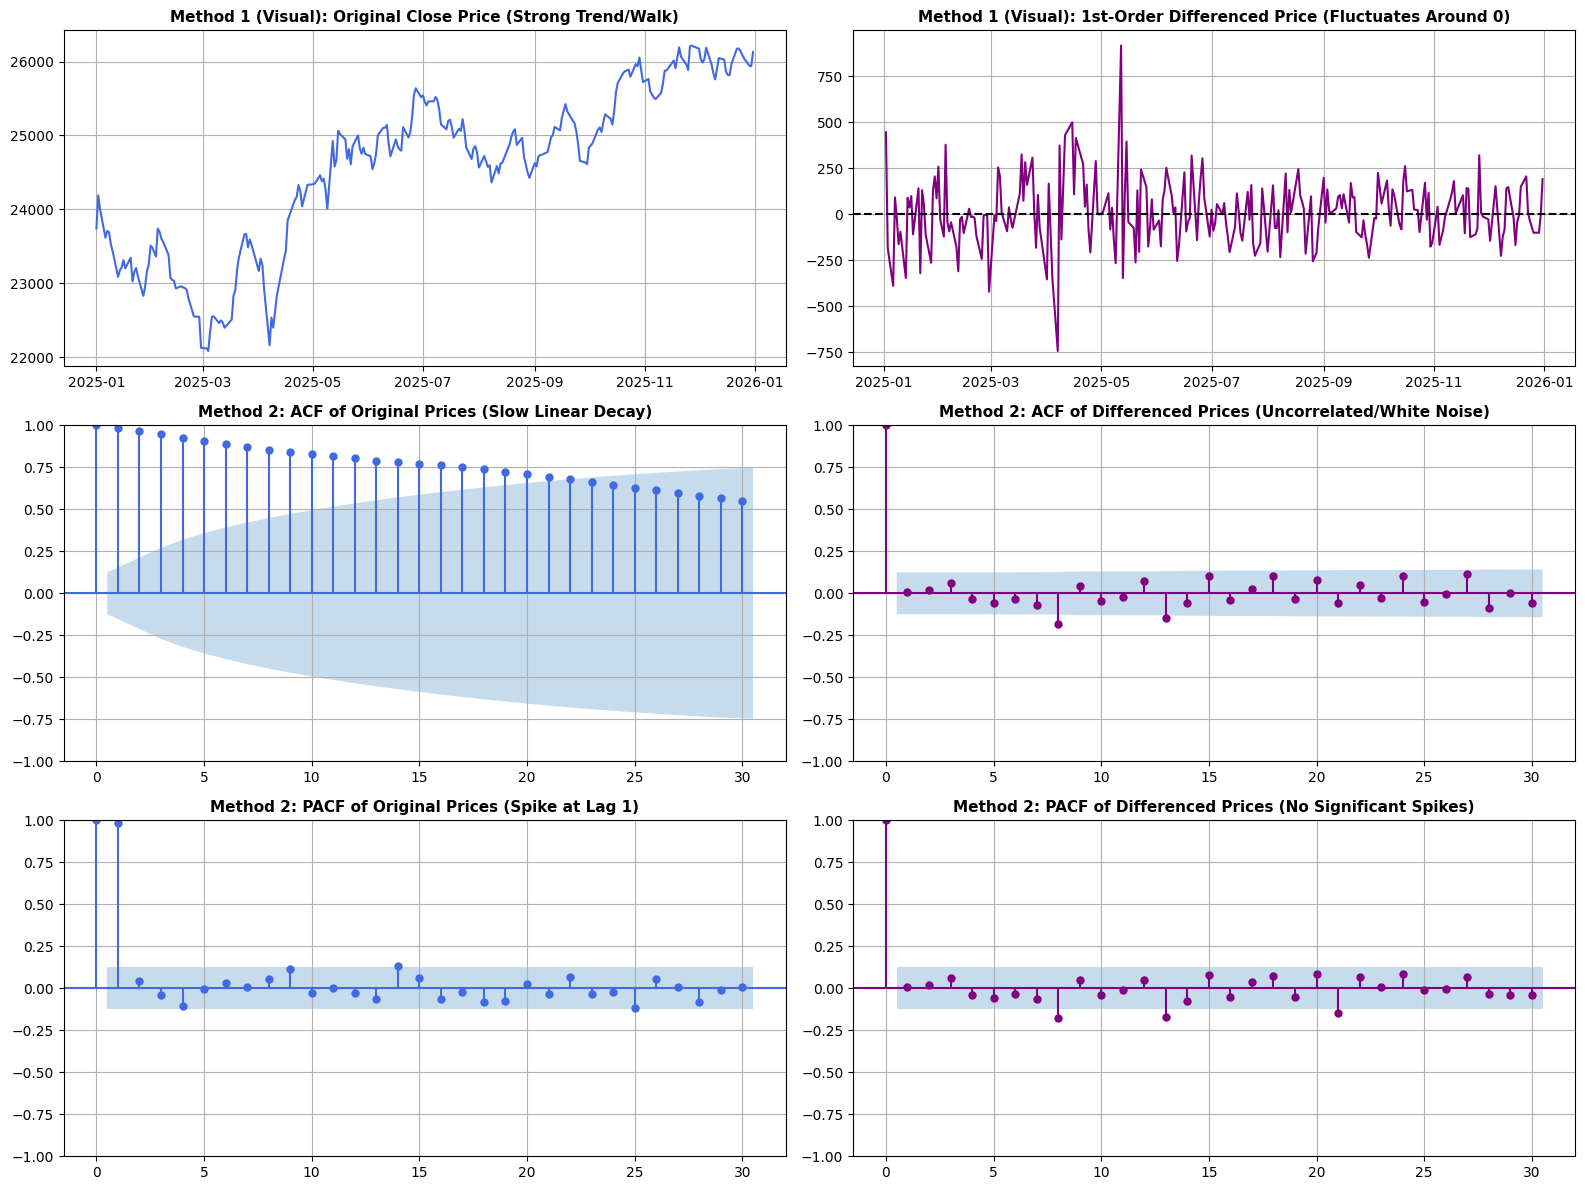

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox

# Prepare data
close_prices = nifty_50['Close'].dropna()
diff_prices = close_prices.diff().dropna()

# Set up a multi-panel visualization comparing Original vs. Differenced Series
fig, axes = plt.subplots(3, 2, figsize=(16, 12))

# ==========================================
# METHOD 1: VISUAL CHECK
# ==========================================
# Original Prices Plot
axes[0, 0].plot(close_prices, color='royalblue')
axes[0, 0].set_title("Method 1 (Visual): Original Close Price (Strong Trend/Walk)", fontsize=11, fontweight='bold')
axes[0, 0].grid(True)

# Differenced Prices Plot
axes[0, 1].plot(diff_prices, color='purple')
axes[0, 1].axhline(y=0, color='black', linestyle='--')
axes[0, 1].set_title("Method 1 (Visual): 1st-Order Differenced Price (Fluctuates Around 0)", fontsize=11, fontweight='bold')
axes[0, 1].grid(True)

# ==========================================
# METHOD 2: ACF & PACF PLOTS
# ==========================================
# Original Prices ACF
sm.graphics.tsa.plot_acf(close_prices, lags=30, ax=axes[1, 0], color='royalblue', vlines_kwargs={"colors": 'royalblue'})
axes[1, 0].set_title("Method 2: ACF of Original Prices (Slow Linear Decay)", fontsize=11, fontweight='bold')
axes[1, 0].grid(True)

# Differenced Prices ACF
sm.graphics.tsa.plot_acf(diff_prices, lags=30, ax=axes[1, 1], color='purple', vlines_kwargs={"colors": 'purple'})
axes[1, 1].set_title("Method 2: ACF of Differenced Prices (Uncorrelated/White Noise)", fontsize=11, fontweight='bold')
axes[1, 1].grid(True)

# Original Prices PACF
sm.graphics.tsa.plot_pacf(close_prices, lags=30, ax=axes[2, 0], color='royalblue', vlines_kwargs={"colors": 'royalblue'})
axes[2, 0].set_title("Method 2: PACF of Original Prices (Spike at Lag 1)", fontsize=11, fontweight='bold')
axes[2, 0].grid(True)

# Differenced Prices PACF
sm.graphics.tsa.plot_pacf(diff_prices, lags=30, ax=axes[2, 1], color='purple', vlines_kwargs={"colors": 'purple'})
axes[2, 1].set_title("Method 2: PACF of Differenced Prices (No Significant Spikes)", fontsize=11, fontweight='bold')
axes[2, 1].grid(True)

plt.tight_layout()
plt.show()

In [26]:
# ==========================================
# METHOD 3: LJUNG-BOX TEST FOR AUTOCORRELATION
# ==========================================
print("=== Method 3: Ljung-Box Test on Original Prices ===")
ljung_orig = acorr_ljungbox(close_prices, lags=[10], return_df=True)
display(ljung_orig)
p_orig = ljung_orig['lb_pvalue'].values[0]
print(f"Verdict: p-value = {p_orig:.4e}. " +
      ("Significant autocorrelation present (Reject H0 -> Random Walk / Non-Stationary)." if p_orig < 0.05 else "No autocorrelation (Fail to reject H0 -> White Noise)."))

print("\n=== Method 3: Ljung-Box Test on 1st-Order Differenced Prices ===")
ljung_diff = acorr_ljungbox(diff_prices, lags=[10], return_df=True)
display(ljung_diff)
p_diff = ljung_diff['lb_pvalue'].values[0]
print(f"Verdict: p-value = {p_diff:.4f}. " +
      ("Significant autocorrelation remains." if p_diff < 0.05 else "No significant autocorrelation (Fail to reject H0 -> White Noise / Stationary)."))

=== Method 3: Ljung-Box Test on Original Prices ===


,lb_stat,lb_pvalue
10,2084.494392,0.0


Verdict: p-value = 0.0000e+00. Significant autocorrelation present (Reject H0 -> Random Walk / Non-Stationary).

=== Method 3: Ljung-Box Test on 1st-Order Differenced Prices ===


,lb_stat,lb_pvalue
10,13.269247,0.209005


Verdict: p-value = 0.2090. No significant autocorrelation (Fail to reject H0 -> White Noise / Stationary).
